# Banking Fraud Detection – Data Analysis


# Introduction
Banking Fraud Detection – Exploratory Data Analysis(EDA)
This project analyzes banking transaction data to understand the patterns and behaviors associated with fraudulent transactions. The analysis focuses on
transaction amount, transaction type, account balance, device type used ,location changes, transaction time, and failed transactions.


# Business Problem
Banking fraud is an important problem because fraudulent transactions can cause financial losses and affect customer trust.The bank wants to identify transaction patterns that are associated with
fraud.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Phase 1 – Understand the Data

In [2]:
#loading the dataset
df=pd.read_csv("/Users/pinnamanenisaisubhash/Downloads/banking_fraud_data.csv")

In [3]:
#Display the first 5 rows.
df.head()

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1
3,TXN000004,CUST01098,54.0,Chennai,11208.39,POS,261985.75,Mobile,No,20.0,No,0.0,0
4,TXN000005,CUST01083,54.0,Bengaluru,12673.87,Online,21390.58,Mobile,No,11.0,No,0.0,0


In [4]:
#Display the last 5 rows.
df.tail()

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
9995,TXN009996,CUST01178,45.0,Hyderabad,20955.86,POS,105949.88,Card,Yes,0.0,No,1.0,0
9996,TXN009997,CUST02492,25.0,Mumbai,22601.72,Online,20853.03,Mobile,No,8.0,No,1.0,0
9997,TXN009998,CUST00883,39.0,Hyderabad,17599.32,Online,113282.82,Laptop,Yes,9.0,No,0.0,0
9998,TXN009999,CUST01414,66.0,Visakhapatnam,6188.04,Online,207406.67,Mobile,Yes,12.0,No,2.0,0
9999,TXN010000,CUST01539,62.0,Chennai,22368.53,Online,23857.63,Mobile,No,8.0,No,0.0,0


In [5]:
#Find the number of rows and columns.
df.shape

(10000, 13)

In [6]:
#Display column names
df.columns

Index(['Transaction_ID', 'Customer_ID', 'Age', 'City', 'Transaction_Amount',
       'Transaction_Type', 'Account_Balance', 'Device_Type', 'Location_Change',
       'Transaction_Time_Hour', 'Is_Weekend', 'Failed_Transactions_Last_24h',
       'Is_Fraud'],
      dtype='object')

In [7]:
#Check data types.

df.dtypes

Transaction_ID                   object
Customer_ID                      object
Age                             float64
City                             object
Transaction_Amount              float64
Transaction_Type                 object
Account_Balance                 float64
Device_Type                      object
Location_Change                  object
Transaction_Time_Hour           float64
Is_Weekend                       object
Failed_Transactions_Last_24h    float64
Is_Fraud                          int64
dtype: object

In [8]:
#Generate dataset information using info().
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Transaction_ID                10000 non-null  object 
 1   Customer_ID                   10000 non-null  object 
 2   Age                           9975 non-null   float64
 3   City                          9980 non-null   object 
 4   Transaction_Amount            9982 non-null   float64
 5   Transaction_Type              9985 non-null   object 
 6   Account_Balance               9978 non-null   float64
 7   Device_Type                   9985 non-null   object 
 8   Location_Change               9988 non-null   object 
 9   Transaction_Time_Hour         9985 non-null   float64
 10  Is_Weekend                    9990 non-null   object 
 11  Failed_Transactions_Last_24h  9985 non-null   float64
 12  Is_Fraud                      10000 non-null  int64  
dtypes:

In [9]:
#Generate statistical summary using describe().
df.describe()

,Age,Transaction_Amount,Account_Balance,Transaction_Time_Hour,Failed_Transactions_Last_24h,Is_Fraud
count,9975.000000,9.982000e+03,9978.000000,9985.000000,9985.000000,10000.000000
mean,45.644311,4.260766e+04,78758.417265,12.959740,0.847872,0.131400
std,14.501716,1.366359e+05,76203.640283,6.102521,0.906370,0.337854
min,12.000000,-4.862600e+03,-19234.130000,-5.000000,0.000000,0.000000
25%,33.000000,7.982452e+03,30835.890000,8.000000,0.000000,0.000000
50%,46.000000,1.428474e+04,55028.580000,13.000000,1.000000,0.000000
75%,58.000000,2.555225e+04,98364.657500,18.000000,1.000000,0.000000
max,108.000000,1.789817e+06,500000.000000,30.000000,5.000000,1.000000


In [10]:
#Identify categorical and numerical columns.
numerical_columns = df.select_dtypes(include=["number"]).columns
print(numerical_columns)


Index(['Age', 'Transaction_Amount', 'Account_Balance', 'Transaction_Time_Hour',
       'Failed_Transactions_Last_24h', 'Is_Fraud'],
      dtype='object')


In [11]:
#Categorical columns
categorical_columns = df.select_dtypes(include=["object"]).columns
print(categorical_columns)

Index(['Transaction_ID', 'Customer_ID', 'City', 'Transaction_Type',
       'Device_Type', 'Location_Change', 'Is_Weekend'],
      dtype='object')


In [12]:
#Find the number of unique customers.
df['Customer_ID'].unique()

array(['CUST00224', 'CUST01935', 'CUST01637', ..., 'CUST00858',
       'CUST01921', 'CUST01654'], dtype=object)

In [13]:
#Find the number of unique transactions.
df['Transaction_ID'].unique()

array(['TXN000001', 'TXN000002', 'TXN000003', ..., 'TXN009998',
       'TXN009999', 'TXN010000'], dtype=object)

In [14]:
#Find unique transaction types.
df['Transaction_Type'].unique()

array(['ATM', 'Online', 'POS', nan], dtype=object)

In [15]:
#Find unique device types.
df['Device_Type'].unique()

array(['ATM', 'Mobile', 'Laptop', 'Card', nan], dtype=object)

In [16]:
# Find unique cities.
df['City'].unique() 

array(['Mumbai', 'Bengaluru', 'Chennai', 'Pune', 'Vijayawada',
       'Hyderabad', 'Delhi', 'Visakhapatnam', nan], dtype=object)


* How many transactions are present?
   10000 transactions

* How many customers are present?
   2451 customers

* What types of transactions are available?
  ATM, Online, POS, nan are available
   
*  Which columns are numerical?
  ['Age', 'Transaction_Amount', 'Account_Balance', 'Transaction_Time_Hour',
       'Failed_Transactions_Last_24h', 'Is_Fraud'] are numerical
 
* Which columns are categorical?
  ['Transaction_ID', 'Customer_ID', 'City', 'Transaction_Type',
       'Device_Type', 'Location_Change', 'Is_Weekend'] are categorical


# Phase 2 – Data Quality Investigation

In [17]:
#Checking the sum of missing values in data
df.isnull().sum()

Transaction_ID                   0
Customer_ID                      0
Age                             25
City                            20
Transaction_Amount              18
Transaction_Type                15
Account_Balance                 22
Device_Type                     15
Location_Change                 12
Transaction_Time_Hour           15
Is_Weekend                      10
Failed_Transactions_Last_24h    15
Is_Fraud                         0
dtype: int64

* Which columns contain missing values?
Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_hour,Is_Weekend,Failed_Transaction_Last_24th

In [18]:
df.isnull().sum().sum()

np.int64(167)

* How many missing values are present?
167 missing values


In [19]:
#returns the duplicated rows 
df.duplicated().sum()

np.int64(0)

In [20]:
# checks the percentage of each columns is missing
df.isnull().sum()/len(df)*100 

Transaction_ID                  0.00
Customer_ID                     0.00
Age                             0.25
City                            0.20
Transaction_Amount              0.18
Transaction_Type                0.15
Account_Balance                 0.22
Device_Type                     0.15
Location_Change                 0.12
Transaction_Time_Hour           0.15
Is_Weekend                      0.10
Failed_Transactions_Last_24h    0.15
Is_Fraud                        0.00
dtype: float64

In [21]:
missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_data

,Missing Values,Missing Percentage
Transaction_ID,0,0.00
Customer_ID,0,0.00
Age,25,0.25
City,20,0.20
Transaction_Amount,18,0.18
Transaction_Type,15,0.15
Account_Balance,22,0.22
Device_Type,15,0.15
Location_Change,12,0.12
Transaction_Time_Hour,15,0.15


In [22]:
#Handling the missing values
df["Age"] = df["Age"].fillna(df["Age"].median())


In [124]:
df["City"] = df["City"].fillna(df["City"].mode()[0])

In [115]:
df["Transaction_Amount"] = df["Transaction_Amount"].fillna(df["Transaction_Amount"].median())

In [116]:
df["Transaction_Type"] = df["Transaction_Type"].fillna(df["Transaction_Type"].mode()[0])

In [117]:
df["Account_Balance"] = df["Account_Balance"].fillna(df["Account_Balance"].median())

In [118]:
df["Device_Type"] = df["Device_Type"].fillna(df["Device_Type"].mode()[0])

In [119]:
df["Location_Change"] = df["Location_Change"].fillna(df["Location_Change"].mode()[0])

In [120]:
df["Transaction_Time_Hour"] = df["Transaction_Time_Hour"].fillna(df["Transaction_Time_Hour"].median())

In [121]:
df["Is_Weekend"] = df["Is_Weekend"].fillna(df["Is_Weekend"].mode()[0])

In [122]:
df["Failed_Transactions_Last_24h"] = df["Failed_Transactions_Last_24h"].fillna(df["Failed_Transactions_Last_24h"].median())

* What percentage of each column is missing?
Transaction_ID                  0.00%
Customer_ID                     0.00%
Age                             0.25%
City                            0.20%
Transaction_Amount              0.18%
Transaction_Type                0.15%
Account_Balance                 0.22%
Device_Type                     0.15%
Location_Change                 0.12%
Transaction_Time_Hour           0.15%
Is_Weekend                      0.10%
Failed_Transactions_Last_24h    0.15%
Is_Fraud                        0.00%

#Explain why you selected your approach?
we can use both mean and meadian for numerical columns.
 I selected median for Age,Transaction Amount,Account Balance,Transaction Time,Failed Transactions these are numerical columns.
 here transaction amount and account balance has very large values when we use mean these extreme values can increase the average whereas the median is less affected by the extreme values and provides the representative values  for filling the missing values .


In [125]:
#check whether all missing  values are filled
df.isnull().sum()

Transaction_ID                  0
Customer_ID                     0
Age                             0
City                            0
Transaction_Amount              0
Transaction_Type                0
Account_Balance                 0
Device_Type                     0
Location_Change                 0
Transaction_Time_Hour           0
Is_Weekend                      0
Failed_Transactions_Last_24h    0
Is_Fraud                        0
Time_Category                   0
Transaction_Ratio               0
Is_High_Value                   0
High_Risk_Time                  0
High_Failed_Attempts            0
Potentially_Suspicious          0
dtype: int64

In [33]:
df.isnull().sum().sum()

np.int64(20)

# Phase 3 – Identify Invalid Data

Transaction Amount
Investigate:
• Negative transaction amounts
• Zero transaction amounts
• Extremely large transactions 

In [34]:
#Check Negative Transaction Amounts
df[df["Transaction_Amount"] < 0]

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
227,TXN000228,CUST01449,70.0,Vijayawada,-1440.99,POS,23841.68,Mobile,No,11.0,No,4.0,1
2284,TXN002285,CUST01703,63.0,Pune,-1691.49,POS,36848.87,Card,No,10.0,No,1.0,0
2415,TXN002416,CUST01216,50.0,Vijayawada,-3551.94,ATM,27364.87,ATM,No,10.0,No,1.0,0
2961,TXN002962,CUST01055,27.0,Chennai,-3676.22,Online,70381.10,Mobile,Yes,10.0,No,0.0,0
4481,TXN004482,CUST00743,45.0,Pune,-3592.13,ATM,16068.63,ATM,No,8.0,No,0.0,0
4905,TXN004906,CUST01604,51.0,Chennai,-2130.04,Online,33677.97,Mobile,Yes,9.0,Yes,0.0,0
5093,TXN005094,CUST02425,38.0,Hyderabad,-2600.43,ATM,35847.23,ATM,Yes,9.0,No,0.0,0
7052,TXN007053,CUST01698,26.0,Bengaluru,-2669.33,Online,50609.11,Laptop,No,21.0,No,0.0,0
7908,TXN007909,CUST00280,63.0,Vijayawada,-1033.30,ATM,172118.86,ATM,No,17.0,No,0.0,0
8242,TXN008243,CUST01372,21.0,Delhi,-1281.55,ATM,500000.00,ATM,No,5.0,No,0.0,0


In [35]:
#check the zero transaction amounts
df[df["Transaction_Amount"] == 0]

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
118,TXN000119,CUST00614,70.0,Bengaluru,0.0,Online,56657.44,Mobile,No,23.0,No,1.0,0
157,TXN000158,CUST01393,29.0,Bengaluru,0.0,POS,228759.41,Card,No,1.0,No,0.0,0
1691,TXN001692,CUST02225,44.0,Bengaluru,0.0,Online,500000.00,Mobile,No,21.0,Yes,0.0,0
1785,TXN001786,CUST00609,29.0,Hyderabad,0.0,Online,33366.52,Laptop,No,21.0,No,1.0,0
4694,TXN004695,CUST01769,38.0,Bengaluru,0.0,Online,52242.09,Laptop,No,21.0,No,1.0,0
4798,TXN004799,CUST00978,41.0,Bengaluru,0.0,Online,33249.33,Mobile,No,8.0,No,0.0,0
5662,TXN005663,CUST02152,47.0,Hyderabad,0.0,Online,284900.31,Mobile,Yes,6.0,Yes,0.0,0
6675,TXN006676,CUST02208,62.0,Pune,0.0,Online,37653.15,Mobile,No,22.0,Yes,0.0,0
8577,TXN008578,CUST02486,22.0,Hyderabad,0.0,Online,102574.71,Mobile,Yes,4.0,No,2.0,0
8607,TXN008608,CUST00876,31.0,Visakhapatnam,0.0,ATM,21599.79,ATM,No,17.0,No,0.0,0


In [36]:
#Check Extremely Large Transaction Amounts
#max() can check the one largest transaction amount
df["Transaction_Amount"].max()


np.float64(1789817.42)

In [37]:
#nlargest(): checks 10 extremely large transaction amounts.
df["Transaction_Amount"].nlargest(10)


6295    1789817.42
2850    1775173.45
6055    1770601.37
1339    1756748.43
6244    1753710.28
108     1735794.67
3585    1725876.82
7140    1719126.61
9720    1712436.22
9359    1705725.99
Name: Transaction_Amount, dtype: float64

Account Balance
Check whether:
• Account balance is negative
• Transaction amount is greater than account balance

In [38]:
#checks whether the account balance is negative
df[df["Account_Balance"] < 0]

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
1262,TXN001263,CUST01112,64.0,Delhi,23181.53,Online,-1350.70,Laptop,No,17.0,No,1.0,0
1317,TXN001318,CUST01476,54.0,Bengaluru,118385.79,POS,-4204.14,Card,No,14.0,Yes,0.0,0
1843,TXN001844,CUST02115,53.0,Chennai,11085.95,Online,-5021.22,Mobile,No,7.0,No,2.0,0
1896,TXN001897,CUST01436,70.0,Pune,52864.09,Online,-11360.53,Laptop,No,9.0,No,0.0,0
2766,TXN002767,CUST00924,26.0,Mumbai,7609.48,POS,-12132.11,Card,No,20.0,No,0.0,0
3620,TXN003621,CUST02491,46.0,Vijayawada,19306.11,POS,-1547.91,Card,No,8.0,No,0.0,0
5280,TXN005281,CUST01783,63.0,Mumbai,62267.87,Online,-18148.87,Laptop,No,8.0,No,1.0,0
6800,TXN006801,CUST02129,62.0,Bengaluru,12371.38,ATM,-8786.60,ATM,No,17.0,No,1.0,0
9031,TXN009032,CUST00751,47.0,Delhi,2568.35,POS,-7995.69,Mobile,No,20.0,No,2.0,0
9282,TXN009283,CUST00310,24.0,Hyderabad,9623.70,Online,-19234.13,Mobile,No,8.0,No,1.0,0


In [39]:
#to check transaction amount is greater than account balance (Transaction Amount > Account Balance)

df["Transaction_Amount"] > df["Account_Balance"]


0        True
1        True
2       False
3       False
4       False
        ...  
9995    False
9996     True
9997    False
9998    False
9999    False
Length: 10000, dtype: bool

In [40]:
#checks if any transaction is greater than account balance
(df["Transaction_Amount"] > df["Account_Balance"]).any()

np.True_

In [41]:
#checking whether all transaction amount is greater than ammount balance
(df["Transaction_Amount"] > df["Account_Balance"]).all()

np.False_

In [42]:
(df["Transaction_Amount"] > df["Account_Balance"]).any()

np.True_

Age
Check whether there are:
• Unrealistic ages
• Extremely low values
• Extremely high values

In [43]:
# checking the sum of unrealistic ages 

print("Unrealistic ages:",((df["Age"] < 18) | (df["Age"] > 100)).sum())

Unrealistic ages: 16


In [44]:
#Extremely low values (checks below 18)

df[df["Age"] < 18]

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
844,TXN000845,CUST00014,17.0,Mumbai,40596.62,Online,33162.56,Laptop,Yes,21.0,Yes,0.0,0
969,TXN000970,CUST00091,12.0,Pune,8816.05,Online,104488.14,Mobile,No,1.0,No,1.0,0
1153,TXN001154,CUST02274,12.0,Bengaluru,9141.24,Online,36086.98,Mobile,Yes,4.0,Yes,1.0,1
1475,TXN001476,CUST00756,17.0,Chennai,11737.98,ATM,500000.00,ATM,No,8.0,No,0.0,0
2223,TXN002224,CUST01058,16.0,Delhi,18917.53,Online,148661.84,Laptop,No,1.0,No,0.0,0
2718,TXN002719,CUST01450,13.0,Mumbai,22646.89,POS,55288.21,Card,No,3.0,Yes,1.0,0
3145,TXN003146,CUST01381,16.0,Chennai,14420.87,Online,113923.35,Mobile,No,7.0,Yes,0.0,0
5304,TXN005305,CUST00586,17.0,Hyderabad,4354.64,Online,90480.28,Laptop,Yes,19.0,Yes,1.0,0
9604,TXN009605,CUST01082,16.0,Pune,6912.32,Online,73241.23,Mobile,No,0.0,Yes,1.0,0


In [45]:
#Extremely high values(above 100)
df[df["Age"] > 100]

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
92,TXN000093,CUST02105,101.0,Chennai,20859.66,Online,7274.77,Mobile,Yes,8.0,Yes,0.0,0
2667,TXN002668,CUST02414,108.0,Visakhapatnam,21765.55,Online,29909.79,Laptop,No,13.0,Yes,0.0,0
3056,TXN003057,CUST02006,103.0,Hyderabad,3759.97,ATM,76004.78,ATM,Yes,19.0,No,2.0,0
4392,TXN004393,CUST00031,108.0,Delhi,11345.25,Online,289655.93,Mobile,No,17.0,No,2.0,0
5500,TXN005501,CUST02365,103.0,Vijayawada,133210.59,ATM,242695.50,ATM,Yes,19.0,Yes,0.0,1
7927,TXN007928,CUST00685,104.0,Mumbai,211916.71,Online,68364.65,Mobile,No,5.0,No,0.0,0
9490,TXN009491,CUST00564,103.0,Vijayawada,22549.64,Online,68118.32,Mobile,Yes,0.0,No,1.0,0


Transaction Time
Verify that:Transaction_Time_Hour is between: 0 and 23

In [46]:
#checking transaction time is below 0
df[df["Transaction_Time_Hour"] < 0]


,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
1054,TXN001055,CUST00192,48.0,Pune,14284.74,Online,44557.83,Mobile,No,-5.0,No,1.0,0
2645,TXN002646,CUST00014,59.0,Mumbai,44943.99,ATM,55108.86,ATM,No,-1.0,Yes,0.0,0
2778,TXN002779,CUST00972,66.0,Hyderabad,22407.00,POS,93409.04,Card,Yes,-2.0,Yes,0.0,1
3607,TXN003608,CUST01734,62.0,Visakhapatnam,11549.51,Online,26615.67,Mobile,Yes,-4.0,No,0.0,0
5700,TXN005701,CUST01558,57.0,Bengaluru,17369.36,POS,63865.46,Card,No,-2.0,No,1.0,0
6046,TXN006047,CUST00282,52.0,Visakhapatnam,12881.41,Online,9316.45,Mobile,No,-1.0,No,1.0,0
7673,TXN007674,CUST01714,50.0,Mumbai,11790.39,Online,31400.08,Mobile,No,-4.0,Yes,1.0,0
8286,TXN008287,CUST00132,46.0,Pune,15299.71,POS,52918.37,Mobile,No,-5.0,Yes,0.0,0


In [47]:
#checking transaction time is above 23
df[df["Transaction_Time_Hour"]<=23]

,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1
3,TXN000004,CUST01098,54.0,Chennai,11208.39,POS,261985.75,Mobile,No,20.0,No,0.0,0
4,TXN000005,CUST01083,54.0,Bengaluru,12673.87,Online,21390.58,Mobile,No,11.0,No,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,TXN009996,CUST01178,45.0,Hyderabad,20955.86,POS,105949.88,Card,Yes,0.0,No,1.0,0
9996,TXN009997,CUST02492,25.0,Mumbai,22601.72,Online,20853.03,Mobile,No,8.0,No,1.0,0
9997,TXN009998,CUST00883,39.0,Hyderabad,17599.32,Online,113282.82,Laptop,Yes,9.0,No,0.0,0
9998,TXN009999,CUST01414,66.0,Visakhapatnam,6188.04,Online,207406.67,Mobile,Yes,12.0,No,2.0,0


In [48]:
#checking the transaction time is between 0 and 23
df[(df["Transaction_Time_Hour"] <0) |(df["Transaction_Time_Hour"]>23)]


,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud
1054,TXN001055,CUST00192,48.0,Pune,14284.74,Online,44557.83,Mobile,No,-5.0,No,1.0,0
1356,TXN001357,CUST00861,22.0,Visakhapatnam,5303.78,Online,35788.51,Laptop,No,30.0,No,0.0,0
2068,TXN002069,CUST00827,50.0,Hyderabad,17800.10,Online,87640.92,Mobile,No,25.0,Yes,0.0,0
2645,TXN002646,CUST00014,59.0,Mumbai,44943.99,ATM,55108.86,ATM,No,-1.0,Yes,0.0,0
2778,TXN002779,CUST00972,66.0,Hyderabad,22407.00,POS,93409.04,Card,Yes,-2.0,Yes,0.0,1
3607,TXN003608,CUST01734,62.0,Visakhapatnam,11549.51,Online,26615.67,Mobile,Yes,-4.0,No,0.0,0
3815,TXN003816,CUST00180,35.0,Hyderabad,10135.65,Online,256865.01,Laptop,No,30.0,Yes,2.0,0
4744,TXN004745,CUST01741,51.0,Mumbai,8064.01,ATM,46004.68,ATM,No,29.0,Yes,0.0,0
4958,TXN004959,CUST02297,57.0,Delhi,8175.98,POS,266818.49,Mobile,Yes,28.0,No,1.0,0
5700,TXN005701,CUST01558,57.0,Bengaluru,17369.36,POS,63865.46,Card,No,-2.0,No,1.0,0


Which records contain invalid values?
Negative and Zero transaction amounts, negative account balance,unrealistic ages,transaction hours between 0 and 23 contains invalid values.


Should these records be removed or corrected?
Invalid records should be corrected if the value is known but if the value cannot be corrected the record may be removed.



What assumptions did you make?
 Age should between 18 and 100, negative transactions amounts are invalid, transaction time should between 0 and 23, Large amouunt of transactions need futher investigations

# Phase 4 – Outlier Detection

Method 1 – Boxplot
Create a boxplot for:Transaction_Amount, Identify potential outliers.

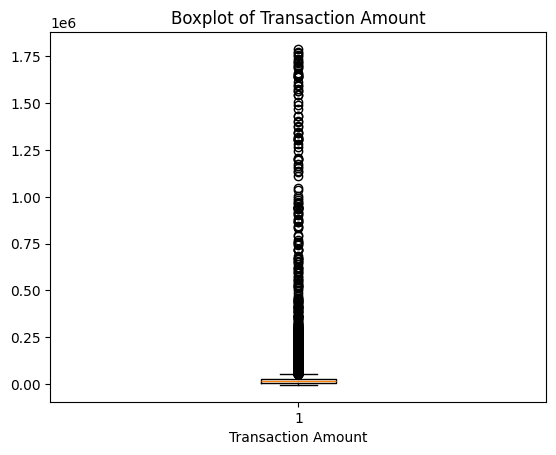

In [49]:
# boxplot using matplolib
plt.boxplot(x=df["Transaction_Amount"])
plt.title("Boxplot of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.show()


* points outside the whiskers are the potential outliers.
* line inside the box is median.

Method 2 – IQR Method
Calculate:
• Q1
• Q3
• IQR
• Lower Bound
• Upper Bound
Formula:
IQR = Q3 - Q1
Lower Bound = Q1 - 1.5 × IQR
Upper Bound = Q3 + 1.5 × IQR
Identify transactions outside these limits.

In [50]:
#calculate the  Q1 of transaction amount
Q1 = df["Transaction_Amount"].quantile(0.25)

print("Q1:", Q1)

Q1: 7991.6275000000005


In [51]:
#calculate the  Q3 
Q3 = df["Transaction_Amount"].quantile(0.75)
print("Q3:", Q3)

Q3: 25516.857500000002


In [52]:
#Calculate the IQR=Q3-Q1
IQR = Q3 - Q1

print("IQR:", IQR)


IQR: 17525.230000000003


In [53]:
#Calculate the Lower Bound = Q1 - 1.5 × IQR
lower_bound = Q1 - 1.5 * IQR

print("Lower Bound:", lower_bound)

Lower Bound: -18296.217500000006


In [54]:
# calculate the Upper Bound = Q3 + 1.5 × IQR
upper_bound = Q3 + 1.5 * IQR

print("Upper Bound:", upper_bound)

Upper Bound: 51804.70250000001


In [55]:
#Identify transactions outside these limits.
outliers = df[ (df["Transaction_Amount"] < lower_bound) |(df["Transaction_Amount"] > upper_bound)]
print(outliers)


     Transaction_ID Customer_ID   Age        City  Transaction_Amount  \
1         TXN000002   CUST01935  27.0   Bengaluru            80057.08   
6         TXN000007   CUST00215  62.0     Chennai           276648.97   
8         TXN000009   CUST00504  24.0        Pune           290207.48   
17        TXN000018   CUST00321  69.0      Mumbai           179124.47   
20        TXN000021   CUST01251  64.0     Chennai           110207.72   
...             ...         ...   ...         ...                 ...   
9951      TXN009952   CUST01030  26.0       Delhi           149776.52   
9969      TXN009970   CUST00769  34.0  Vijayawada           126453.17   
9974      TXN009975   CUST01385  33.0  Vijayawada           151703.31   
9976      TXN009977   CUST00507  22.0       Delhi            87266.61   
9981      TXN009982   CUST00018  56.0       Delhi            66889.61   

     Transaction_Type  Account_Balance Device_Type Location_Change  \
1              Online         67506.61      Mobile   

In [56]:
#outliers of the transaction amount
len(outliers)

1238

* How many outliers are present?
1238 

* Which transactions are outliers?
 using the IQR Method ,the transaction amount which is greater than the upper bound of 51804.70250000001 and below the lower bound is considered as outliers.


 * Are all outliers fraudulent?
 No, an outlier should not automatically be considered fraud,the transaction should be investigated

In [57]:
outliers["Is_Fraud"].value_counts()

Is_Fraud
0    939
1    299
Name: count, dtype: int64

* Should an outlier automatically be considered fraud?
No,an outlier should not automatically be considered fraud.

* Is an outlier necessarily an error?
No,we should not remove an extreme transaction automatically. 

* A ₹10,00,000 transaction may be unusual, but it could still be a legitimate transaction.
We should investigate it first and determine whether it is a genuine transaction or an error.

 # Phase 5 – NumPy Analysis

Use NumPy to perform numerical analysis.
Calculate:
• Mean transaction amount
• Median transaction amount
• Standard deviation
• Minimum transaction amount
• Maximum transaction amount
• Percentiles

In [58]:
#change dataframe of transaction amt into numpy array
amount = df["Transaction_Amount"].to_numpy()


In [59]:
#calculate the mean of transaction amount 
mean = np.mean(amount)
print("Mean transaction amount:",mean)

Mean transaction amount: 42556.675618999994


In [60]:
#calculate the median transaction amount
median = np.median(amount)

print("Median Transaction Amount:", median)

Median Transaction Amount: 14284.74


In [61]:
#calculate standard deviation
std = np.std(amount)
print("Standard Deviation:", std)

Standard Deviation: 136511.28572408637


In [62]:
#checks the Minimum Transaction Amount
minimum = np.min(amount)

print("Minimum Transaction Amount:", minimum)

Minimum Transaction Amount: -4862.6


In [63]:
#checks the Maximum Transaction Amount
maximum = np.max(amount)

print("Maximum Transaction Amount:", maximum)

Maximum Transaction Amount: 1789817.42


In [64]:
# calculating Percentiles of 25,50,70 and 90th 
percentiles = np.percentile(amount, [25, 50, 75, 90])

print("25th Percentile:", percentiles[0])
print("50th Percentile:", percentiles[1])
print("75th Percentile:", percentiles[2])
print("90th Percentile:", percentiles[3])

25th Percentile: 7991.6275000000005
50th Percentile: 14284.74
75th Percentile: 25516.857500000002
90th Percentile: 74673.74300000005


In [65]:
#changing df into numpy 
fraud = df[df["Is_Fraud"] == 1]["Transaction_Amount"].to_numpy()

non_fraud = df[df["Is_Fraud"] == 0]["Transaction_Amount"].to_numpy()

In [66]:
#calculate the mean
print("Mean Fraud:", np.mean(fraud))
print("Mean Non-Fraud:", np.mean(non_fraud))

Mean Fraud: 73647.40528158295
Mean Non-Fraud: 37853.33475132397


In [67]:
#calculate the meadian
print("Median Fraud:", np.median(fraud))
print("Median Non-Fraud:", np.median(non_fraud))

Median Fraud: 19183.155
Median Non-Fraud: 13802.485


In [68]:
#calculate the standard deviation
print("Standard Deviation Fraud:", np.std(fraud))
print("Standard Deviation Non-Fraud:", np.std(non_fraud))


Standard Deviation Fraud: 191982.5407217743
Standard Deviation Non-Fraud: 125341.12855626196


* Is the average transaction amount higher for fraudulent transactions?
Support your answer with calculations.
* I compared with mean,meadian ,std of transaction amount for fraund and non fraud .
Yes,Fraudulent transactions have a higher average transaction amount than non fraudulent transactions.




# Phase 6 – Fraud Distribution Analysis
Analyze the target variable:
Is_Fraud
Determine:
• Number of fraudulent transactions
• Number of legitimate transactions
• Fraud percentage

In [69]:
#to check the no.of fraudulent transactions
df["Is_Fraud"].value_counts()

Is_Fraud
0    8686
1    1314
Name: count, dtype: int64

0 = Non-Fraudulent
1 = Fraudulent

In [70]:
#no.of fraudulent transactions
fraud_count = (df["Is_Fraud"] == 1).sum()

print("Fraud Transactions:", fraud_count)

Fraud Transactions: 1314


In [71]:
#checking Number of legitimate transactions
legitimate_transactions = (df["Is_Fraud"] == 0).sum()

print("Number of legitimate transactions:", legitimate_transactions)

Number of legitimate transactions: 8686


In [72]:
#calculate fraud percentage 
fraud_percentage = (df["Is_Fraud"] == 1).mean() * 100

print("Fraud Percentage:", fraud_percentage)


Fraud Percentage: 13.139999999999999


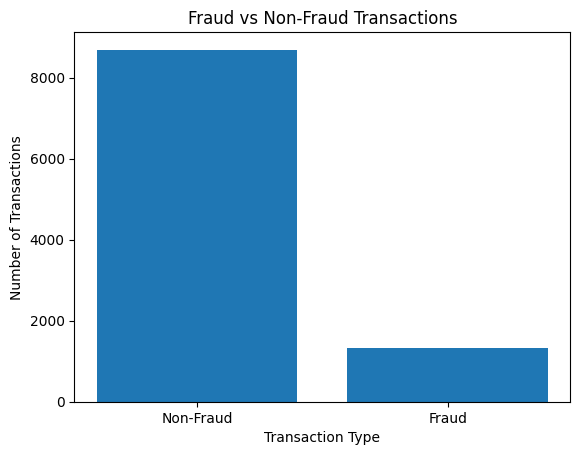

In [73]:
#creating Fraud vs Non-Fraud Visualization
fraud_counts = df["Is_Fraud"].value_counts()

plt.bar(["Non-Fraud", "Fraud"], fraud_counts.values)

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.show()

* Is the dataset balanced or imbalanced?
It is imbalanced dataset because there are 1314 fraud transactions and 8686 non-fraud transactions both datasets are very different


* Why could class imbalance become a problem in a real fraud detection system?
It can be a problem because a model may predict most
transactions as non-fraud and still achieve high accuracy while missing
many fraudulent transactions.

# Phase 7 – Fraud by Transaction Type
Analyze fraud across:
• Online
• ATM
• POS
Create an appropriate visualization.

In [74]:
df["Transaction_Type"].value_counts()

Transaction_Type
Online    5173
POS       2502
ATM       2325
Name: count, dtype: int64

In [75]:
#checking no.of fraud cases
fraud_cases = df.groupby("Transaction_Type")["Is_Fraud"].sum()

print(fraud_cases)

Transaction_Type
ATM       239
Online    828
POS       247
Name: Is_Fraud, dtype: int64


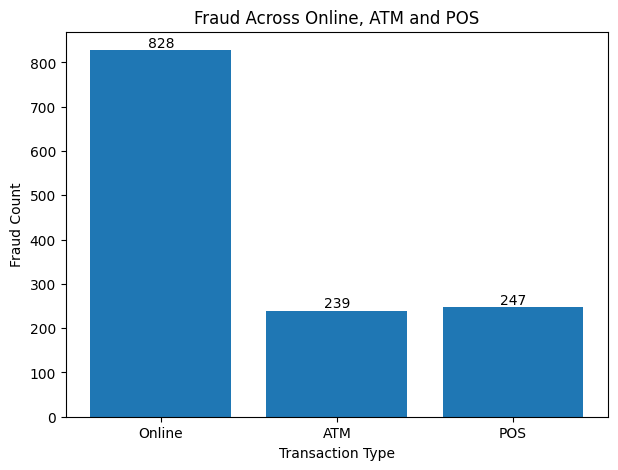

In [76]:
#creating visualization to analyze online,ATM,POS fraud 
types = ['Online', 'ATM', 'POS']
values = df.groupby("Transaction_Type")["Is_Fraud"].sum().reindex(types).tolist()

plt.figure(figsize=(7, 5))

bars = plt.bar(types, values)

plt.xlabel("Transaction Type")
plt.ylabel("Fraud Count")
plt.title("Fraud Across Online, ATM and POS")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.show()

In [77]:
#checking the fraud rate
fraud_rate = df.groupby("Transaction_Type")["Is_Fraud"].mean() * 100

print(fraud_rate)

Transaction_Type
ATM       10.279570
Online    16.006186
POS        9.872102
Name: Is_Fraud, dtype: float64


Text(0, 0.5, 'Fraud Rate (%)')

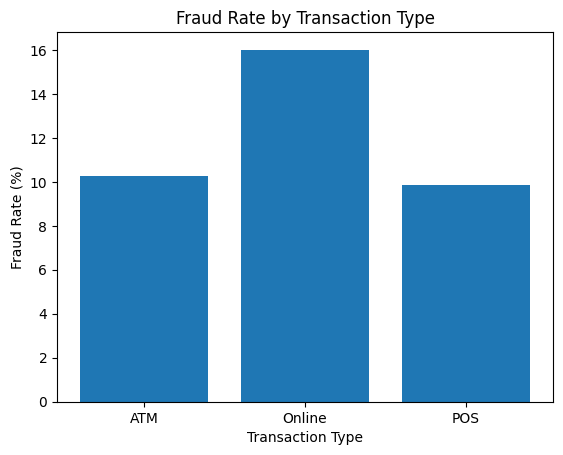

In [78]:
#creating a visualizations of fraud rate
plt.bar(fraud_rate.index, fraud_rate.values)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")

* Which transaction type has the highest number of fraud cases?
online transactions type has the highest no.of fraud cases

* Which transaction type has the highest fraud rate?
Online has the highest fraud rate.

* Is online banking more risky than ATM/POS?
Yes. Online banking has a fraud rate, which is higher than both ATM and POS.

# Phase 8 – Device Analysis
Analyze fraud based on:
• Mobile
• Laptop
• ATM
• Card
Create suitable visualizations.

In [79]:
#checking the total transaction of device type
df["Device_Type"].value_counts()

Device_Type
Mobile    3971
ATM       2327
Card      2001
Laptop    1701
Name: count, dtype: int64

In [80]:
#checking fraud cases by device type
fraud_by_device = df.groupby("Device_Type")["Is_Fraud"].sum()

print(fraud_by_device)

Device_Type
ATM       238
Card      181
Laptop    223
Mobile    672
Name: Is_Fraud, dtype: int64


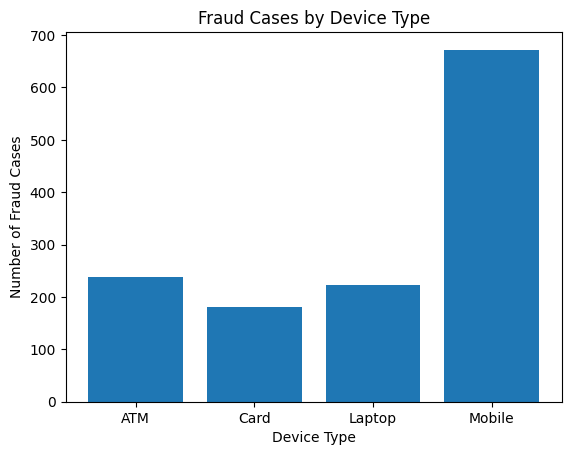

In [81]:
#creating a visualization of fraud cases by device type

plt.bar(fraud_by_device.index, fraud_by_device.values)

plt.title("Fraud Cases by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Number of Fraud Cases")

plt.show()

In [82]:
#checking fraud rate by device 
fraud_rate_device = df.groupby("Device_Type")["Is_Fraud"].mean() * 100

print(fraud_rate_device)

Device_Type
ATM       10.227761
Card       9.045477
Laptop    13.109935
Mobile    16.922689
Name: Is_Fraud, dtype: float64


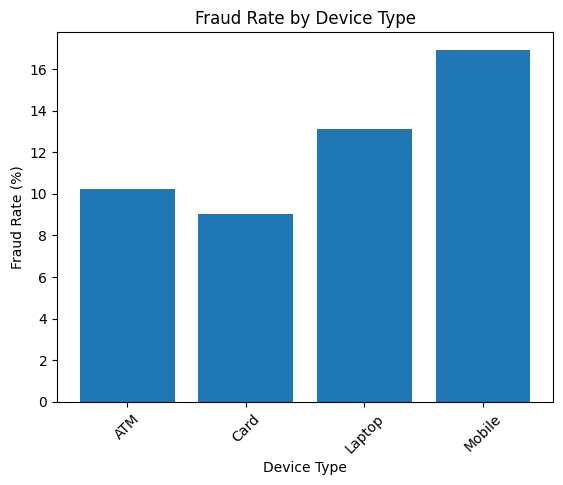

In [83]:
#creating a visualization of fraud rate by device type
plt.bar(fraud_rate_device.index, fraud_rate_device.values)
plt.xticks(rotation=45)
plt.title("Fraud Rate by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Fraud Rate (%)")

plt.show()

* Which device is associated with the highest fraud?
Mobile is associated with highest fraud


* Does the device type appear to influence fraud?
Device type appears to be associated with different levels of fraud in this dataset.

In [84]:
fraud_rate_device = df.groupby("Device_Type")["Is_Fraud"].mean() * 100

print(fraud_rate_device)

Device_Type
ATM       10.227761
Card       9.045477
Laptop    13.109935
Mobile    16.922689
Name: Is_Fraud, dtype: float64


* What percentage of transactions from each device are fraudulent?
ATM       10.227761
Card       9.045477
Laptop    13.109935
Mobile    16.922689



# Phase 9 – Location Change Analysis
Analyze:
Location_Change
Compare:
• Location changed
• Location did not change

In [85]:
#check the counts of location change 
df["Location_Change"].value_counts()  

Location_Change
No     7848
Yes    2152
Name: count, dtype: int64

location_fraud = df.groupby("Location_Change")["Is_Fraud"].mean() * 100

print(location_fraud)

* Are transactions involving a location change more likely to be fraudulent?
yes ,transaction involving a location change more likely to be fraudulent.


* Create a visualization and calculate the fraud percentage for each group.
fraud percentage is 27.23% when the location changes and 9.28% when location did not change .

In [86]:
fraud_percentage = df.groupby("Location_Change")["Is_Fraud"].mean() * 100

print(fraud_percentage)

Location_Change
No      9.276249
Yes    27.230483
Name: Is_Fraud, dtype: float64


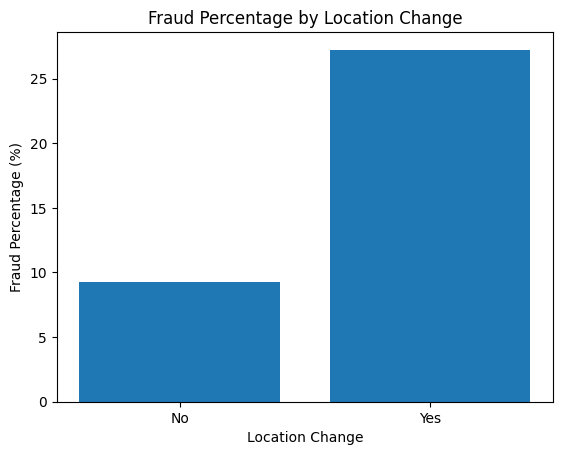

In [87]:
#visualization of fraud percentage
plt.bar(fraud_percentage.index, fraud_percentage.values)

plt.title("Fraud Percentage by Location Change")
plt.xlabel("Location Change")
plt.ylabel("Fraud Percentage (%)")

plt.show()

# Phase 10 – Transaction Time Analysis
Analyze:
Transaction_Time_Hour
Create a new column:
Time_Category
Suggested categories:
Morning → 5–11
Afternoon → 12–16
Evening → 17–20
Night → 21–23
Late Night → 0–4
Analyze fraud across different time periods.

In [88]:
#checking the transaction hours

df["Transaction_Time_Hour"].head()

0    10.0
1    17.0
2     4.0
3    20.0
4    11.0
Name: Transaction_Time_Hour, dtype: float64

In [89]:
#create a new column time_category and adding suggesting cagetories to it
def time_category(hour):
    if 5 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 16:
        return "Afternoon"
    elif 17 <= hour <= 20:
        return "Evening"
    elif 21 <= hour <= 23:
        return "Night"
    else:
        return "Late Night"

In [90]:
#applying Time_category to tansaction_time_hour
df["Time_Category"] = df["Transaction_Time_Hour"].apply(time_category)

In [91]:
#checking the Time_category 
df[["Transaction_Time_Hour", "Time_Category"]].head(10)

,Transaction_Time_Hour,Time_Category
0,10.0,Morning
1,17.0,Evening
2,4.0,Late Night
3,20.0,Evening
4,11.0,Morning
5,0.0,Late Night
6,21.0,Night
7,15.0,Afternoon
8,7.0,Morning
9,20.0,Evening


In [92]:
#checking how many transactions are in each category.
df["Time_Category"].value_counts()

Time_Category
Morning       3395
Afternoon     2296
Evening       2211
Night         1211
Late Night     887
Name: count, dtype: int64

In [93]:
#checking the mean of fraud rate time
fraud_rate_time = df.groupby("Time_Category")["Is_Fraud"].mean() * 100

print(fraud_rate_time)

Time_Category
Afternoon     12.238676
Evening       11.488014
Late Night    22.660654
Morning       12.930781
Night         11.478117
Name: Is_Fraud, dtype: float64


In [94]:
#checking no.of fraud cases based on time category
fraud_cases_time = df.groupby("Time_Category")["Is_Fraud"].sum()

print(fraud_cases_time)


Time_Category
Afternoon     281
Evening       254
Late Night    201
Morning       439
Night         139
Name: Is_Fraud, dtype: int64


* During which time period does fraud occur most frequently?
At morning time period fraud cases occurs more frequently


* Are late-night transactions more suspicious?
Latenight transactions are considered more suspicious if their fraud rate is higher than time periods


* Is transaction time a useful fraud indicator?
Yes, transaction time can be a useful fraud indicator if the fraud rates are different across the time categories.


# Phase 11 – Failed Transactions Analysis
Failed_Transactions_Last_24h Compare failed transactions with fraud status. Create a visualization.

In [95]:
# checking the failed transactions
df["Failed_Transactions_Last_24h"].value_counts().sort_index()

Failed_Transactions_Last_24h
0.0    4215
1.0    3714
2.0    1562
3.0     413
4.0      76
5.0      20
Name: count, dtype: int64

In [96]:
# checking the avg no.of failed transactions for fraud cases
fraud_avg = df[df["Is_Fraud"] == 1]["Failed_Transactions_Last_24h"].mean()

print("Average failed transactions for fraud cases:", fraud_avg)

Average failed transactions for fraud cases: 0.9802130898021308


In [97]:
#Compare failed transactions with fraud
fraud_rate_failed = df.groupby("Failed_Transactions_Last_24h")["Is_Fraud"].mean() * 100

print(fraud_rate_failed)

Failed_Transactions_Last_24h
0.0    12.384342
1.0    12.654820
2.0    11.459667
3.0    28.571429
4.0    25.000000
5.0    30.000000
Name: Is_Fraud, dtype: float64


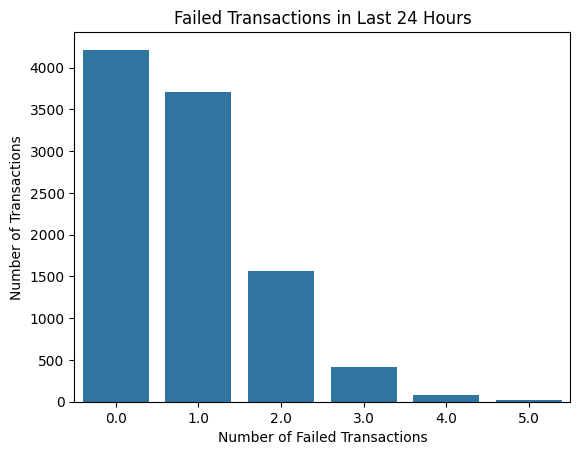

In [98]:
# creating a visualization on number of failed transactions
sns.countplot(data=df, x="Failed_Transactions_Last_24h")
plt.title("Failed Transactions in Last 24 Hours")
plt.xlabel("Number of Failed Transactions")
plt.ylabel("Number of Transactions")
plt.show()

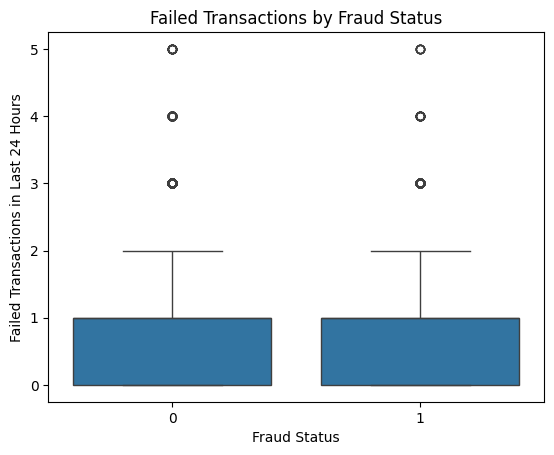

In [99]:
# creating a visualization comparing different number of failed transactions
sns.boxplot(data=df,x="Is_Fraud",y="Failed_Transactions_Last_24h")
plt.title("Failed Transactions by Fraud Status")
plt.xlabel("Fraud Status")
plt.ylabel("Failed Transactions in Last 24 Hours")
plt.show()

* Do fraudulent transactions have more failed attempts?
Fraudulent transactions have more failed attempts on average if their average number of failed transactions is higher than that of non-fraudulent transactions.

* What is the average number of failed transactions for fraud cases?
Average failed transactions for fraud cases: 0.9802130898021308

* Does a higher number of failed transactions indicate increased risk?
yes,a higher number of failed transactions indicate increased risk if fraud percentage increases as the number of failed transactions
increases. 


# Phase 12 – Correlation Analysis

Select appropriate numerical columns and create a correlation matrix.
Use:
Seaborn Heatmap
Analyze relationships between:
• Transaction Amount
• Account Balance
• Age
• Transaction Time
• Failed Transactions
• Is_Fraud

In [100]:
#selecting the numerical columns
corr_data = df[
    ["Transaction_Amount",
     "Account_Balance",
     "Age",
     "Transaction_Time_Hour",
     "Failed_Transactions_Last_24h",
     "Is_Fraud"]
]

In [101]:
#creating the correlation matrix 
correlation = corr_data.corr()

correlation

,Transaction_Amount,Account_Balance,Age,Transaction_Time_Hour,Failed_Transactions_Last_24h,Is_Fraud
Transaction_Amount,1.000000,0.034224,-0.003347,-0.018422,-0.014912,0.088583
Account_Balance,0.034224,1.000000,-0.012005,-0.008735,0.012665,-0.046086
Age,-0.003347,-0.012005,1.000000,0.015718,0.018123,0.000556
Transaction_Time_Hour,-0.018422,-0.008735,0.015718,1.000000,-0.012441,-0.064474
Failed_Transactions_Last_24h,-0.014912,0.012665,0.018123,-0.012441,1.000000,0.056737
Is_Fraud,0.088583,-0.046086,0.000556,-0.064474,0.056737,1.000000


In [102]:
# check  correlation the Is_fraud 
correlation["Is_Fraud"].sort_values(ascending=False)

Is_Fraud                        1.000000
Transaction_Amount              0.088583
Failed_Transactions_Last_24h    0.056737
Age                             0.000556
Account_Balance                -0.046086
Transaction_Time_Hour          -0.064474
Name: Is_Fraud, dtype: float64

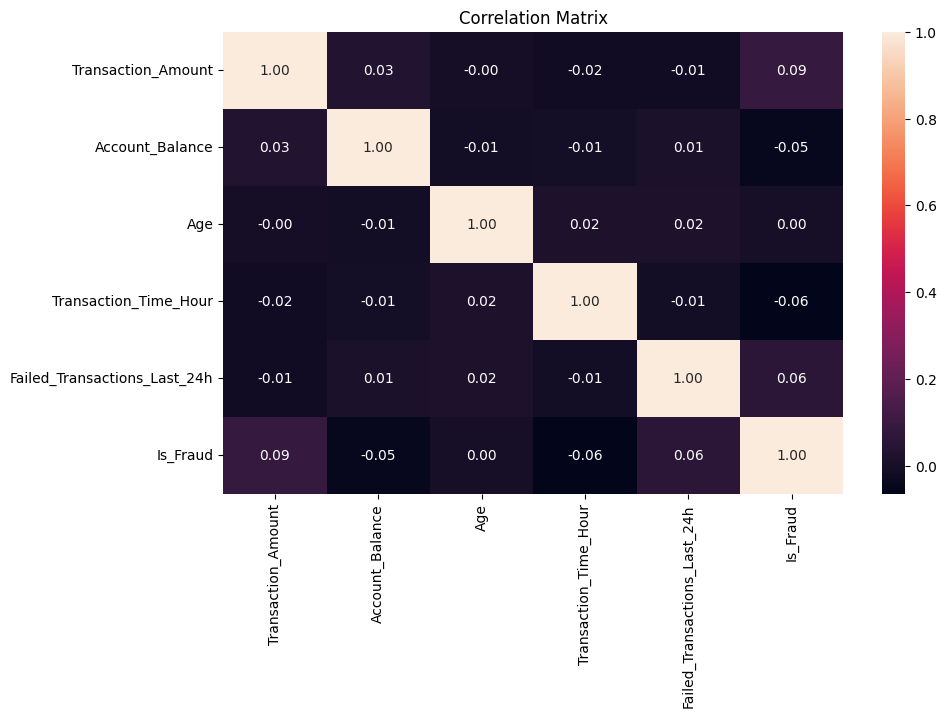

In [103]:
# creating a seaborn heatmap of numerical columns
plt.figure(figsize=(10, 6))
sns.heatmap(correlation,annot=True,fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

* Which variables have the strongest relationship with fraud?
Fraud transactions have the strongest relationship with fraud

* Which variables appear unrelated?
variable with correlation values close to zero appear unrelated


* Are there highly correlated independent variables?
There are no highly correlated independent variables in the selected numerical variables.

# Phase 13 – Visualization Dashboard

Create a mini analytical dashboard using Matplotlib and Seaborn.
Your dashboard should contain at least:
Visualization 1
Fraud vs Non-Fraud
Visualization 2
Fraud by Transaction Type
Visualization 3
Fraud by Device Type
Visualization 4
Transaction Amount Distribution
Visualization 5
Transaction Amount by Fraud Status
Visualization 6
Fraud by Time Category
Visualization 7
Fraud vs Location Change
Visualization 8
Correlation Heatmap

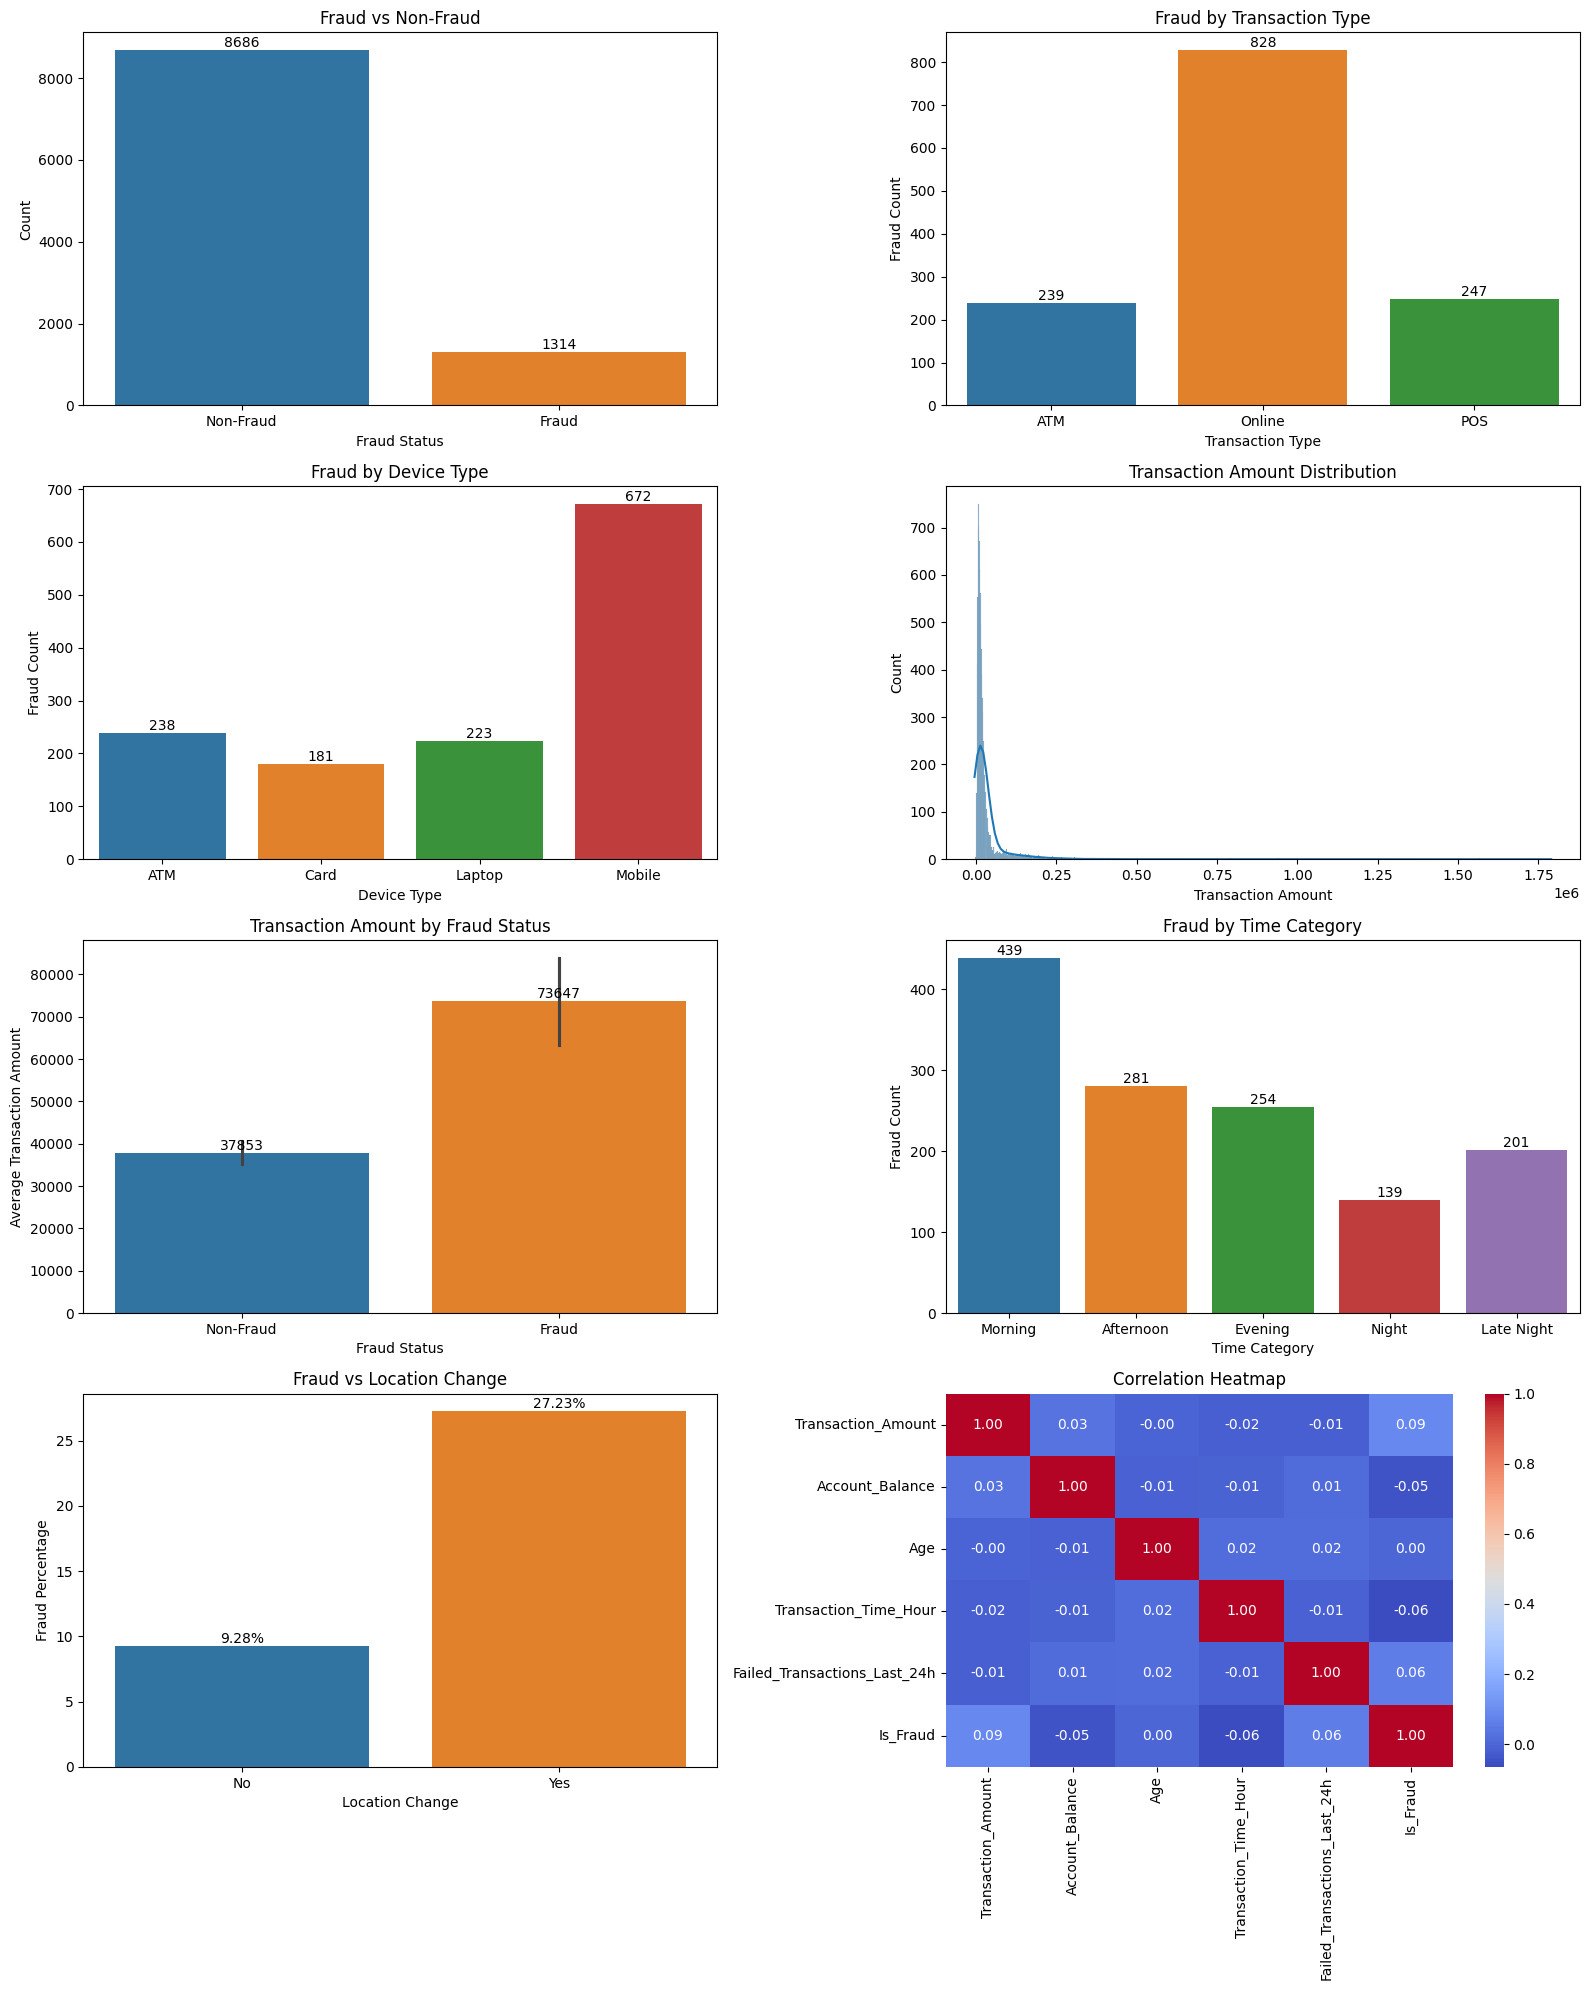

In [104]:
plt.figure(figsize=(16, 20))


#  Fraud vs Non-Fraud
plt.subplot(4, 2, 1)

ax = sns.countplot(
    x='Is_Fraud',
    hue='Is_Fraud',
    data=df,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])
plt.xlabel('Fraud Status')
plt.ylabel('Count')
plt.title('Fraud vs Non-Fraud')


# Fraud by Transaction Type
plt.subplot(4, 2, 2)

fraud_transaction = df.groupby('Transaction_Type')['Is_Fraud'].sum()

ax = sns.barplot(
    x=fraud_transaction.index,
    y=fraud_transaction.values,
    hue=fraud_transaction.index,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.xlabel('Transaction Type')
plt.ylabel('Fraud Count')
plt.title('Fraud by Transaction Type')


#  Fraud by Device Type
plt.subplot(4, 2, 3)

fraud_device = df.groupby('Device_Type')['Is_Fraud'].sum()

ax = sns.barplot(
    x=fraud_device.index,
    y=fraud_device.values,
    hue=fraud_device.index,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.xlabel('Device Type')
plt.ylabel('Fraud Count')
plt.title('Fraud by Device Type')


#  Transaction Amount Distribution
plt.subplot(4, 2, 4)

sns.histplot(
    data=df,
    x='Transaction_Amount',
    kde=True
)

plt.xlabel('Transaction Amount')
plt.ylabel('Count')
plt.title('Transaction Amount Distribution')


#  Transaction Amount by Fraud Status
plt.subplot(4, 2, 5)

ax = sns.barplot(
    x='Is_Fraud',
    y='Transaction_Amount',
    hue='Is_Fraud',
    data=df,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])
plt.xlabel('Fraud Status')
plt.ylabel('Average Transaction Amount')
plt.title('Transaction Amount by Fraud Status')


# Fraud by Time Category
plt.subplot(4, 2, 6)

fraud_time = df.groupby('Time_Category')['Is_Fraud'].sum()

time_order = [
    'Morning',
    'Afternoon',
    'Evening',
    'Night',
    'Late Night'
]

fraud_time = fraud_time.reindex(time_order)

ax = sns.barplot(
    x=fraud_time.index,
    y=fraud_time.values,
    hue=fraud_time.index,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.xlabel('Time Category')
plt.ylabel('Fraud Count')
plt.title('Fraud by Time Category')


#  Fraud vs Location Change
plt.subplot(4, 2, 7)

location_fraud = df.groupby('Location_Change')['Is_Fraud'].mean() * 100

ax = sns.barplot(
    x=location_fraud.index,
    y=location_fraud.values,
    hue=location_fraud.index,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')

plt.xlabel('Location Change')
plt.ylabel('Fraud Percentage')
plt.title('Fraud vs Location Change')


#  Correlation Heatmap
plt.subplot(4, 2, 8)

corr = df[
    [
        'Transaction_Amount',
        'Account_Balance',
        'Age',
        'Transaction_Time_Hour',
        'Failed_Transactions_Last_24h',
        'Is_Fraud'
    ]
].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')


plt.tight_layout()
plt.show()

# Phase 14 – Feature Engineering

In [105]:
#Feature 1 – Transaction Ratio 
#Transaction_Ratio = Transaction_Amount / Account_Balance
df["Transaction_Ratio"] = (
    df["Transaction_Amount"] / df["Account_Balance"]
)


In [106]:
#Feature 2 – High Value Transaction
df['Is_High_Value']=df['Transaction_Amount'].apply(lambda x:'Yes' if x>100000 else 
                                                   'No')

In [107]:
#Feature 3 – High Risk Time
df["High_Risk_Time"] = np.where(
    df["Transaction_Time_Hour"].between(0, 4),
    "Yes",
    "No"
)

In [108]:
#Feature 4 – High Failed Attempts
df["High_Failed_Attempts"] = np.where(
    df["Failed_Transactions_Last_24h"] >= 3,
    "Yes",
    "No"
)

In [109]:
df[["Failed_Transactions_Last_24h", "High_Failed_Attempts"]].head()

,Failed_Transactions_Last_24h,High_Failed_Attempts
0,0.0,No
1,0.0,No
2,1.0,No
3,0.0,No
4,0.0,No


In [110]:
#checking added coloumns
df[
    [
        "Transaction_Ratio",
        "Is_High_Value",
        "High_Risk_Time",
        "High_Failed_Attempts"
    ]
].head()

,Transaction_Ratio,Is_High_Value,High_Risk_Time,High_Failed_Attempts
0,1.724314,No,No,No
1,1.185915,No,No,No
2,0.259133,No,Yes,No
3,0.042782,No,No,No
4,0.592498,No,No,No


# Phase 15 – Identify Suspicious Transactions

In [111]:
#Create the suspicious flag
df["Potentially_Suspicious"] = np.where(
    (df["Transaction_Amount"] > 100000) |
    (df["Location_Change"] == "Yes") |
    (df["High_Risk_Time"] == "Yes") |
    (df["High_Failed_Attempts"] == "Yes") |
    (df["Transaction_Ratio"] > 1),
    "Yes",
    "No"
)

In [112]:
df["Potentially_Suspicious"].value_counts()

Potentially_Suspicious
No     5550
Yes    4450
Name: count, dtype: int64

In [113]:
#checking suspicious transactions
suspicious = df[df["Potentially_Suspicious"] == "Yes"]
suspicious.head()


,Transaction_ID,Customer_ID,Age,City,Transaction_Amount,Transaction_Type,Account_Balance,Device_Type,Location_Change,Transaction_Time_Hour,Is_Weekend,Failed_Transactions_Last_24h,Is_Fraud,Time_Category,Transaction_Ratio,Is_High_Value,High_Risk_Time,High_Failed_Attempts,Potentially_Suspicious
0,TXN000001,CUST00224,51.0,Mumbai,20165.96,ATM,11695.06,ATM,No,10.0,Yes,0.0,0,Morning,1.724314,No,No,No,Yes
1,TXN000002,CUST01935,27.0,Bengaluru,80057.08,Online,67506.61,Mobile,Yes,17.0,No,0.0,0,Evening,1.185915,No,No,No,Yes
2,TXN000003,CUST01637,37.0,Bengaluru,11593.67,POS,44740.16,Mobile,Yes,4.0,Yes,1.0,1,Late Night,0.259133,No,Yes,No,Yes
5,TXN000006,CUST02147,22.0,Chennai,44335.95,Online,59945.82,Mobile,No,0.0,No,1.0,0,Late Night,0.739600,No,Yes,No,Yes
6,TXN000007,CUST00215,62.0,Chennai,276648.97,Online,98553.66,Mobile,No,21.0,No,0.0,1,Night,2.807090,Yes,No,No,Yes


# Final Business Questions

* What are the strongest indicators of fraudulent transactions?
Location Change,Late-night transactions,High failed attempts,high transaction are strongest indicators of fradualent transactions.


* Are high-value transactions more likely to be fraudulent?
Yes,High-value transactions appear to have a higher fraud risk in this dataset.

* Does a location change indicate higher fraud risk?
Yes,fraud risk is 27.23% when location changes and 9.28% when location did not change 

* Does transaction time influence fraud?
Transaction time can be useful fraud indicator, mostly for late-night transactions.

* Does the number of failed transactions correlate with fraud?
Yes,The correlation between Failed_Transactions_Last_24h and Is_Fraud is approximately 0.057, which is a weak positive correlation.

* Which transaction type has the highest fraud rate? 
Online has the highest fraud rate.

* Which device type has the highest fraud rate?
Mobile has the highest fraud rate.

* Are outliers necessarily fraudulent?
NO,Outliers should be investigated, but they should not automatically be classified as fraudulent

* Which variables should the bank monitor more closely?
The bank monitor more closely to location change,Transaction Amount,Transaction Time,failed transactions,transaction type,device type,Transaction-to-Account-Balance Ratio 

* What recommendations would you give to the bank? 
Transactions with multiple failed attempts should receive additional verification,Online and mobile transactions should be monitored

#  Final Conclusion

* "Based on the data, what patterns should the bank monitor to identify potentially
fraudulent transactions?"

 # Key Findings

 1. Transactions with multiple failed attempts show increased fraud risk
 2. Online and mobile transactions have higher fraud rates than other transaction and device types.
3. High-value transactions show a higher risk of fraud and should be checked.
4. Late-night transactions have a higher fraud rate compared with other time periods.
5. Location changes are associated with a higher fraud rate than transactions without a location change.

# Business Recommendations
1. Transactions with multiple failed attempts should receive Two-Step verification.
2. The bank should regularly update its fraud detection rules based on the latest transaction patterns.
3. The bank should closely monitor high-value, late-night, and location-change transactions.
